# 02 · Spatial and temporal refinement

Apply spatial Area filtering and spatial/temporal clustering to every NNA group above the configured minimum size. The algorithm retains a full event ledger, so excluded members and candidate groups below the final size threshold remain visible.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

here = Path.cwd().resolve()
root = next((p for p in (here, *here.parents) if (p / "run_aspect.py").is_file()), None)
assert root is not None, "Open the notebook from within the ASPECT repository."
sys.path.insert(0, str(root / "notebooks"))
import regional_utils as w
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

w.run_stage("dbscan")
files = w.refined_files()
assert files, "No NNA group met the configured refinement threshold."
records = []
for path in files:
    df = pd.read_csv(path)
    candidate = df.final_cluster.ge(0)
    retained = df.refined_cluster.ge(0)
    spatial = df.spatial_excluded.astype(bool)
    records.append({"file": path.name, "input": len(df), "spatial_excluded": int(spatial.sum()),
                    "temporal_noise": int((~spatial & ~candidate).sum()),
                    "below_final_size": int((candidate & ~retained).sum()),
                    "retained": int(retained.sum()), "retained_groups": int(df.loc[retained, "refined_cluster"].nunique())})
ledger = pd.DataFrame(records)
assert (ledger.input == ledger[["spatial_excluded", "temporal_noise", "below_final_size", "retained"]].sum(axis=1)).all()
print("Event accounting for every refined NNA group:")
with pd.option_context("display.max_rows", None, "display.max_colwidth", 100): display(ledger)
print("Totals:")
display(ledger.drop(columns="file").sum().to_frame("events / groups"))

--- Processing ST-DBSCAN for QTM ---
  [Refine] Summary: 1 initial -> 1 optimized clusters.
  [Refine] Summary: 1 initial -> 1 optimized clusters.
  [Refine] Summary: 1 initial -> 1 optimized clusters.
  [Refine] Summary: 2 initial -> 1 optimized clusters.
  [Refine] Summary: 2 initial -> 0 optimized clusters.
  [Refine] Summary: 1 initial -> 1 optimized clusters.
  [Refine] Summary: 1 initial -> 1 optimized clusters.
  [Refine] Summary: 1 initial -> 1 optimized clusters.
  [Refine] Summary: 3 initial -> 1 optimized clusters.
  [Refine] Summary: 3 initial -> 1 optimized clusters.
  [Refine] Summary: 2 initial -> 0 optimized clusters.
  [Refine] Summary: 1 initial -> 1 optimized clusters.
  [Refine] Summary: 1 initial -> 0 optimized clusters.
  [Refine] Summary: 1 initial -> 1 optimized clusters.
  [Refine] Summary: 1 initial -> 1 optimized clusters.
  [Refine] Summary: 1 initial -> 1 optimized clusters.
  [Refine] Summary: 1 initial -> 1 optimized clusters.
  [Refine] Summary: 1 initia

,file,input,spatial_excluded,temporal_noise,below_final_size,retained,retained_groups
0,refined_QTM_C10286.0_20090923_M2.0_Direct.csv,52,0,7,45,0,0
1,refined_QTM_C11283.0_20091116_M3.6_Direct.csv,93,2,6,0,85,1
2,refined_QTM_C12359.0_20100109_M2.6_Direct.csv,59,4,4,0,51,1
3,refined_QTM_C12438.0_20100112_M4.3_Direct.csv,88,5,1,0,82,1
4,refined_QTM_C13448.0_20100311_M3.5_Direct.csv,261,3,7,0,251,1
5,refined_QTM_C13999.0_20100405_M2.8_Direct.csv,67,2,9,0,56,1
6,refined_QTM_C15491.0_20100603_M3.2_Direct.csv,63,0,4,0,59,1
7,refined_QTM_C15697.0_20100613_M4.2_Direct.csv,147,12,5,0,130,1
8,refined_QTM_C15993.0_20100625_M1.4_Direct.csv,58,0,8,0,50,1
9,refined_QTM_C16103.0_20100629_M1.9_Direct.csv,72,2,1,69,0,0


Totals:


,events / groups
input,16907
spatial_excluded,622
temporal_noise,917
below_final_size,1794
retained,13574
retained_groups,61


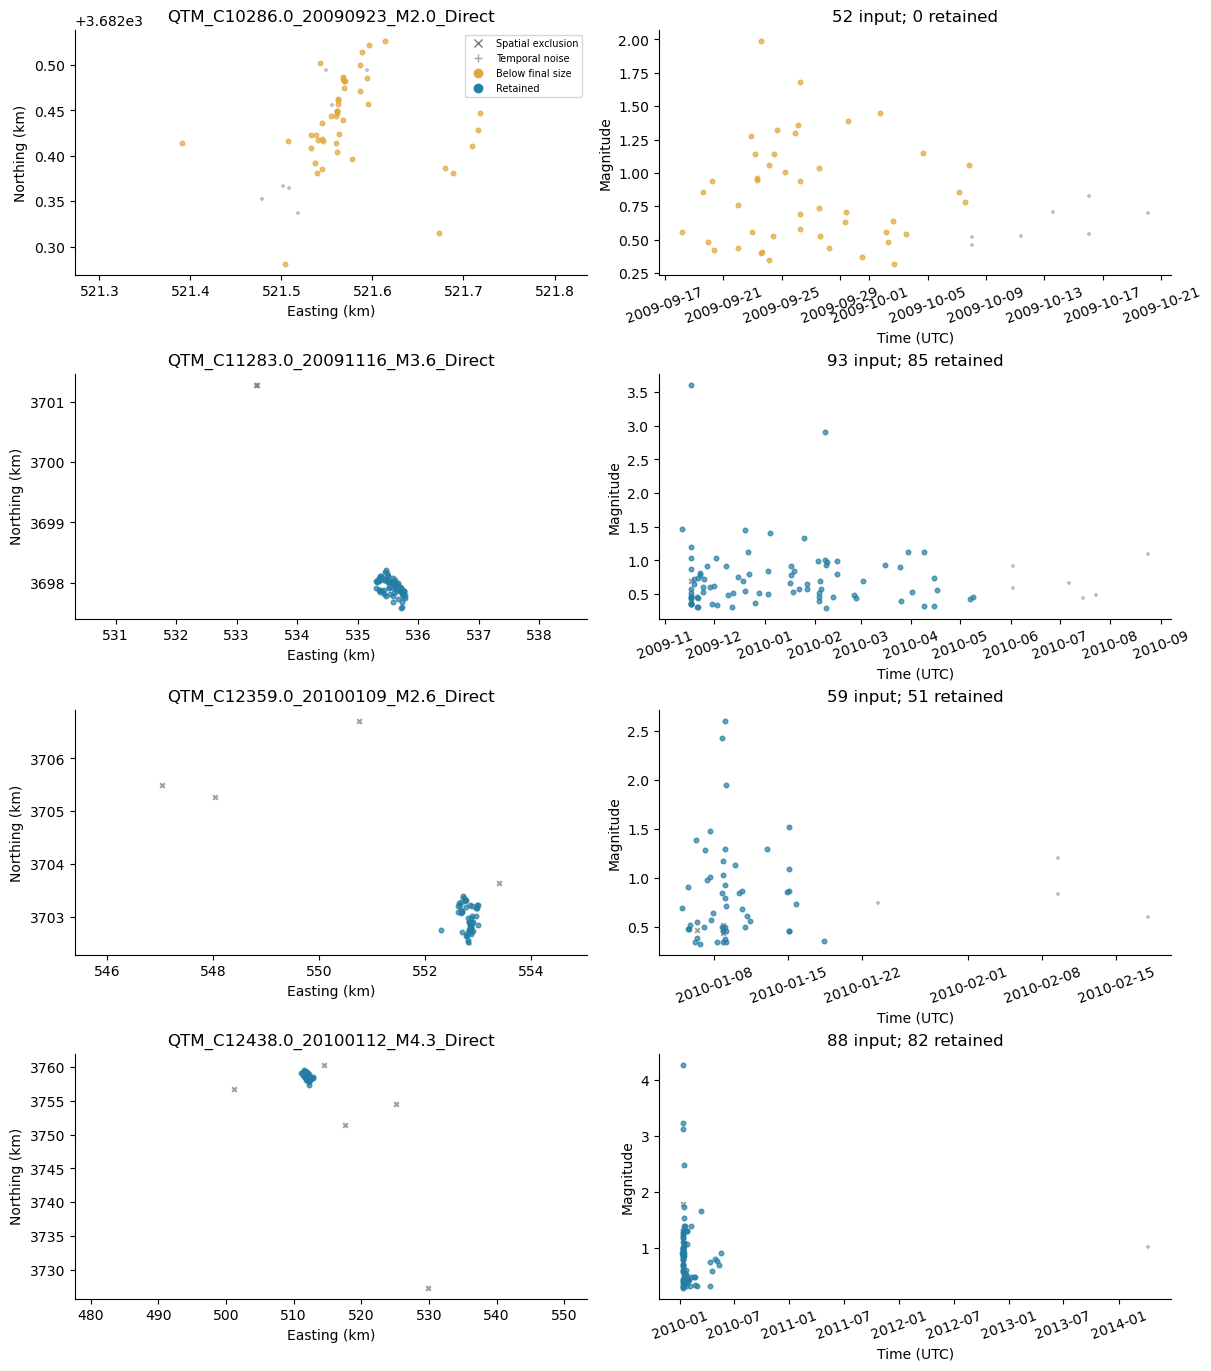

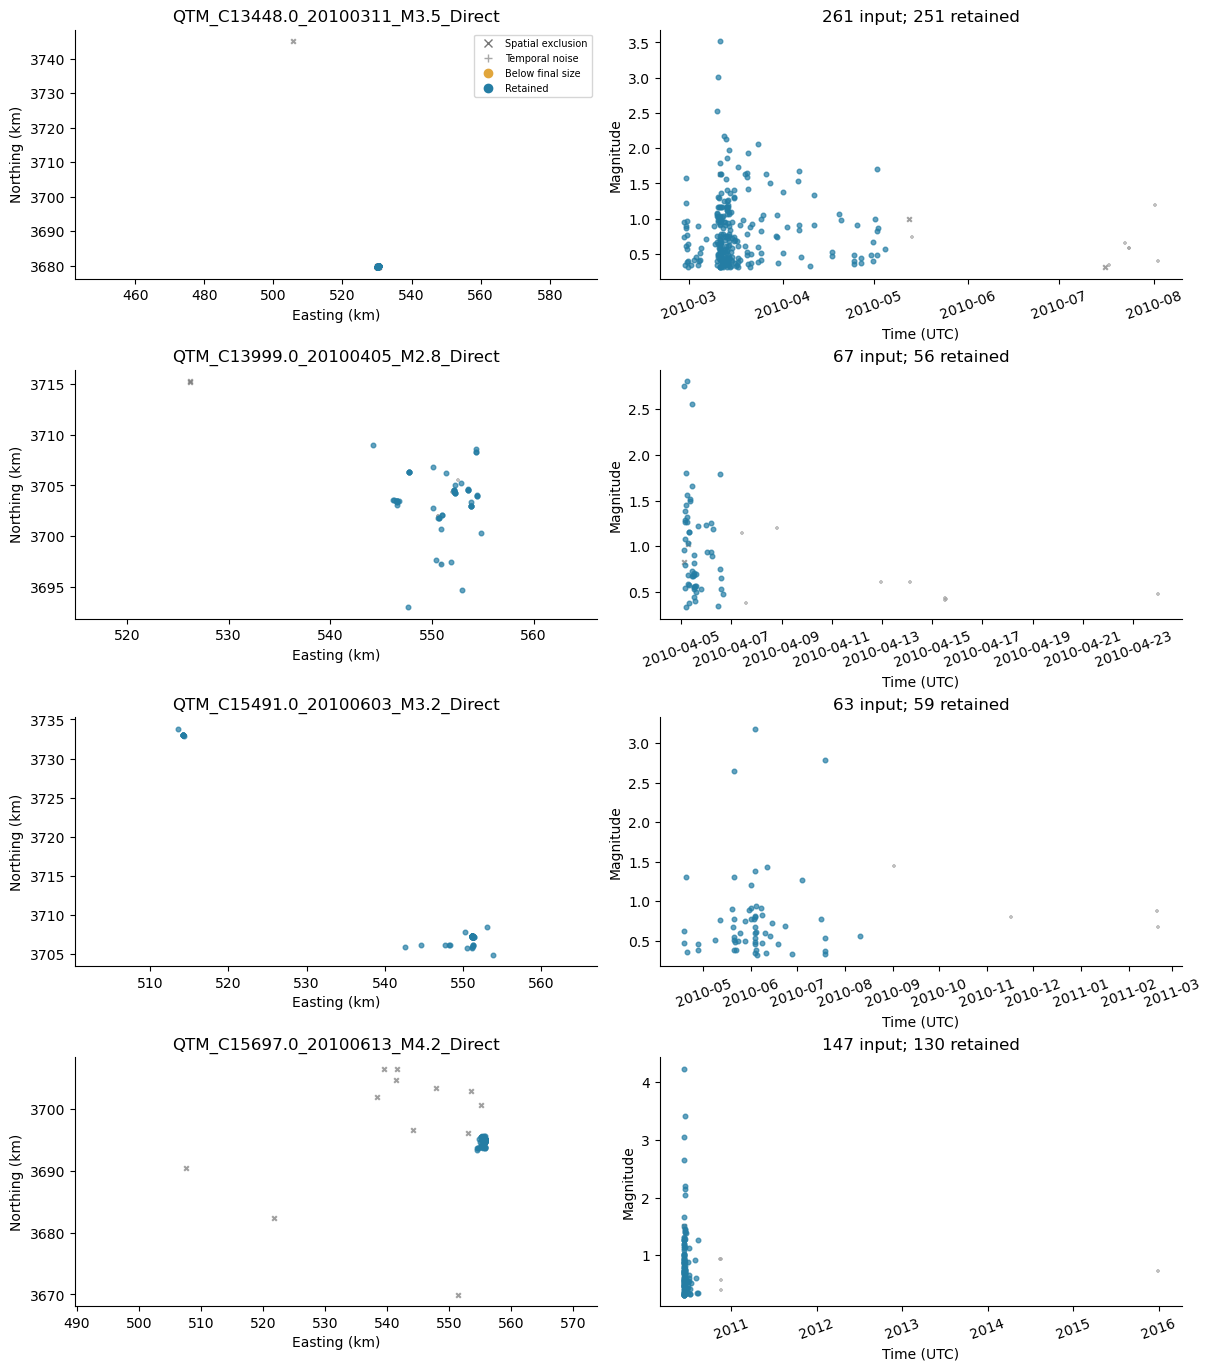

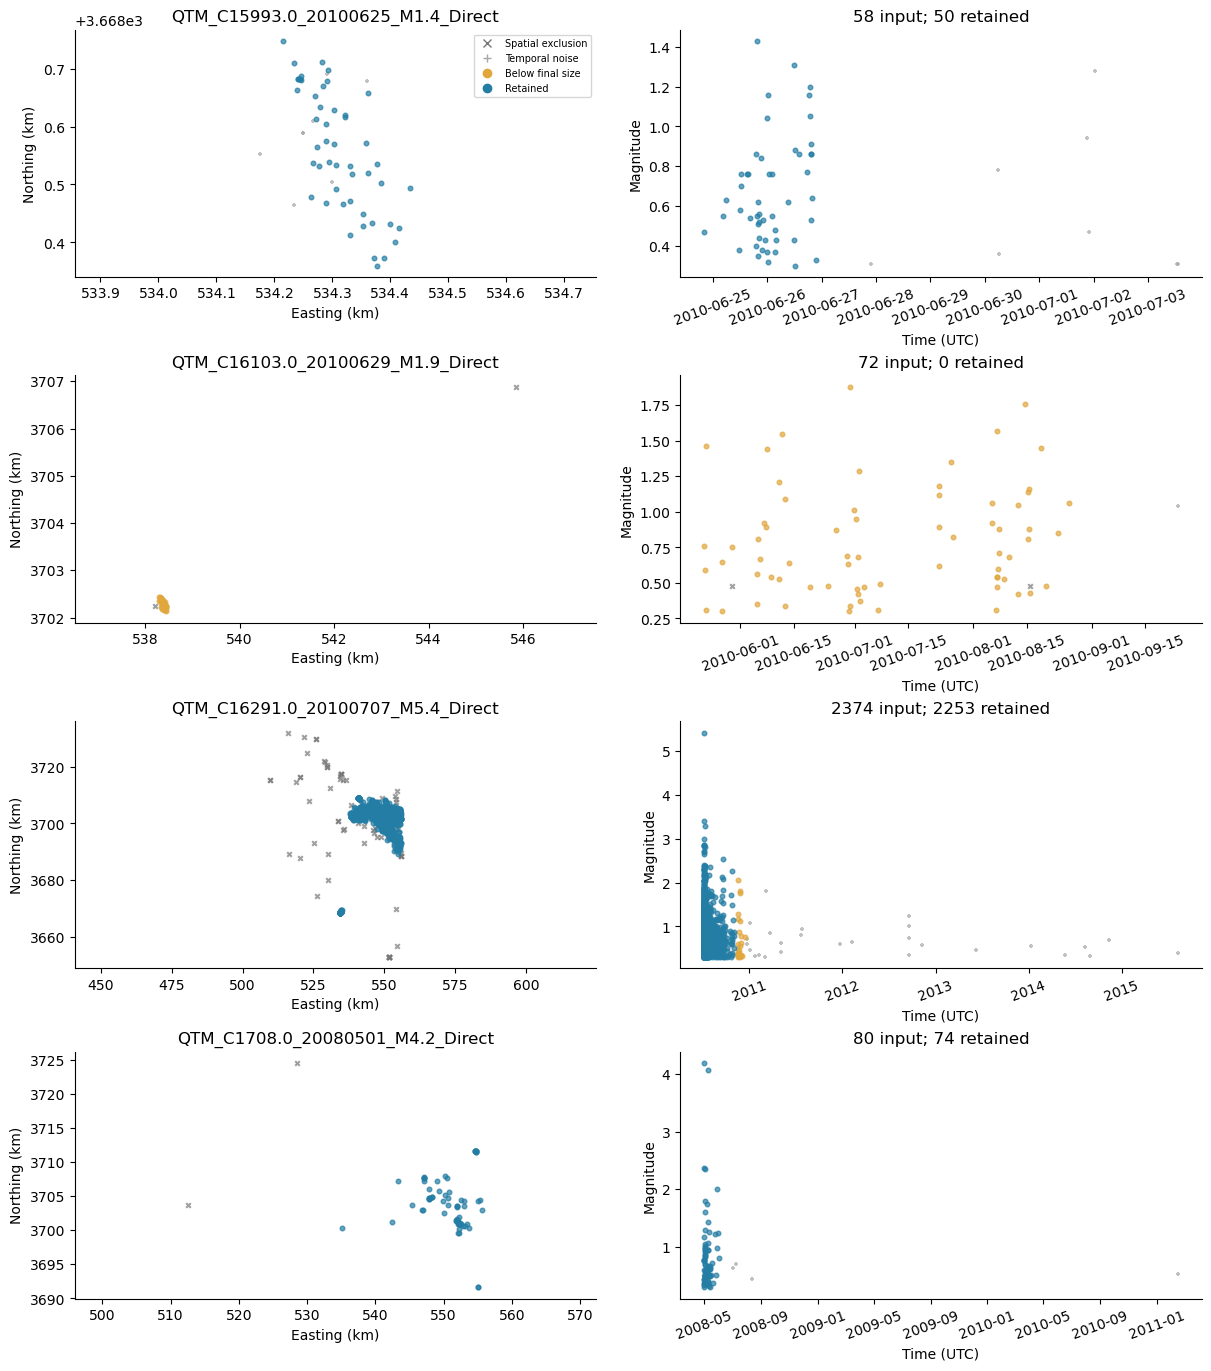

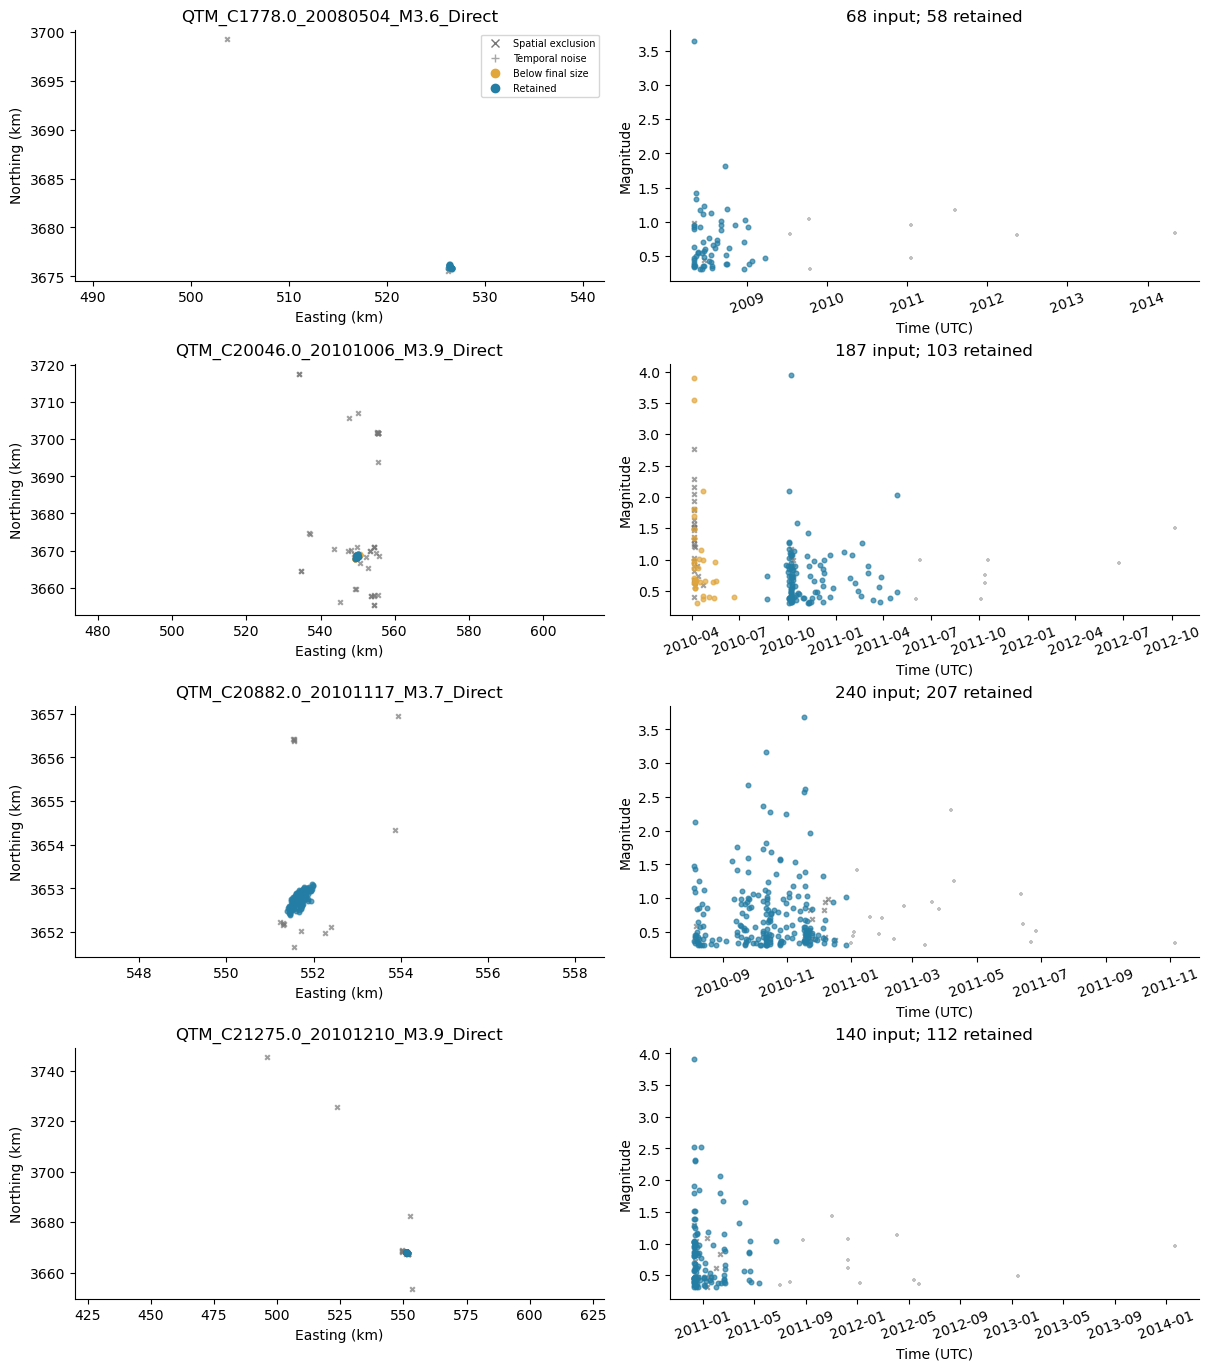

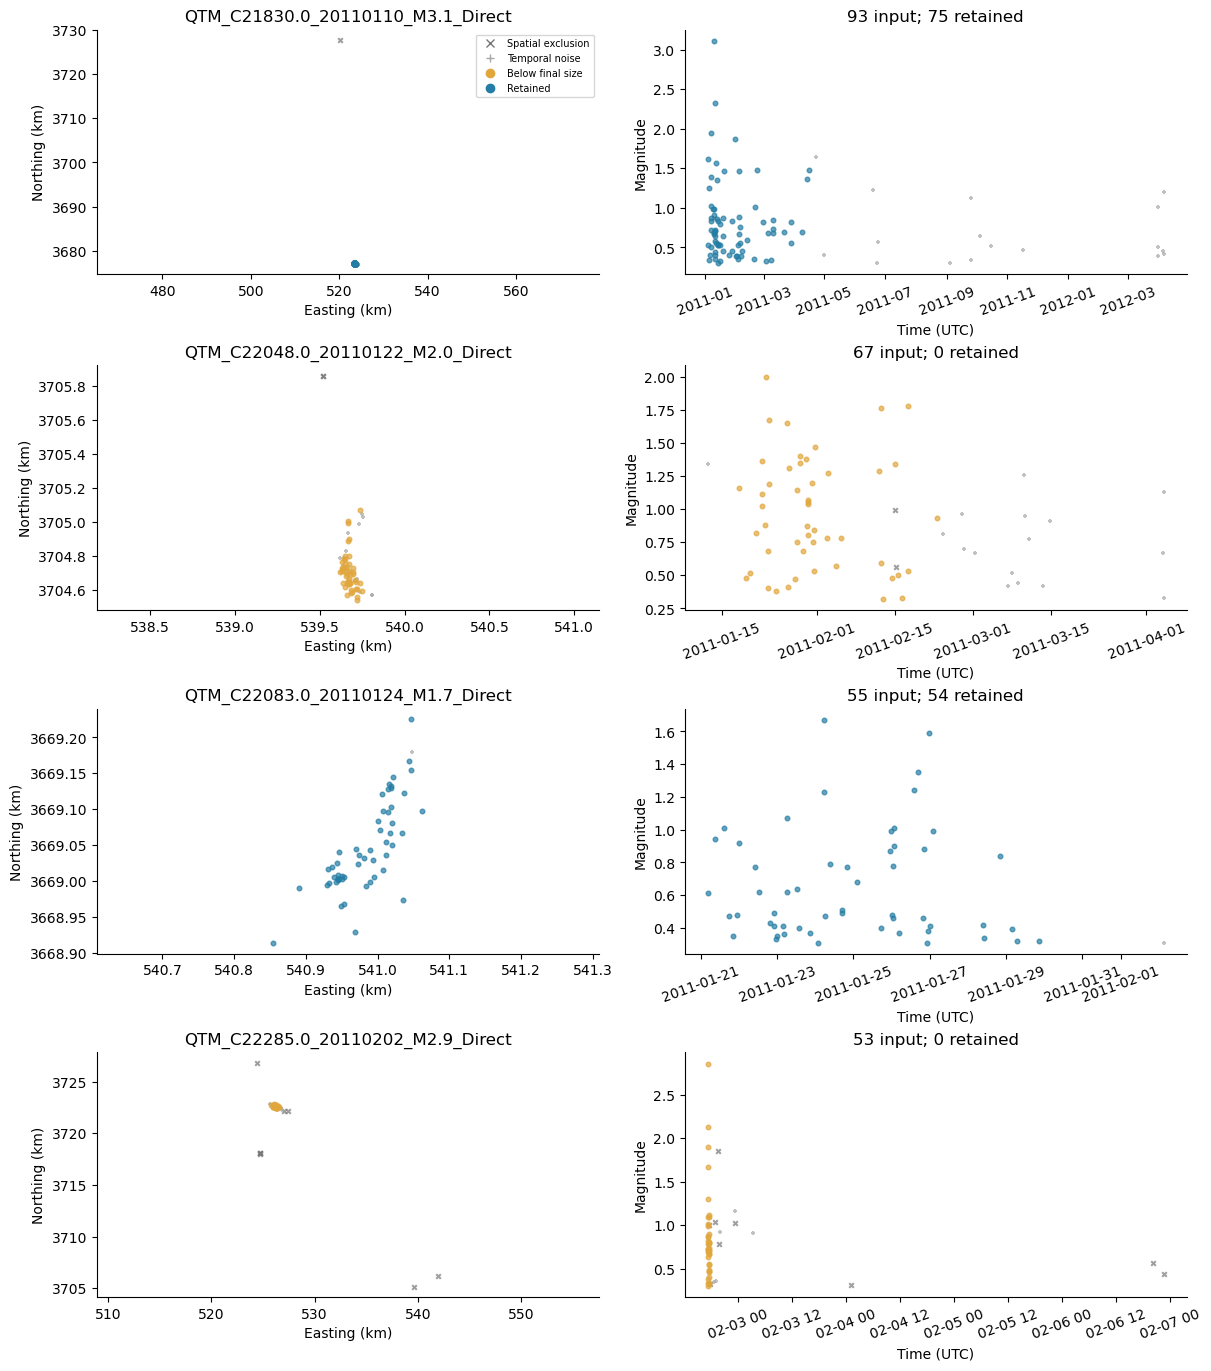

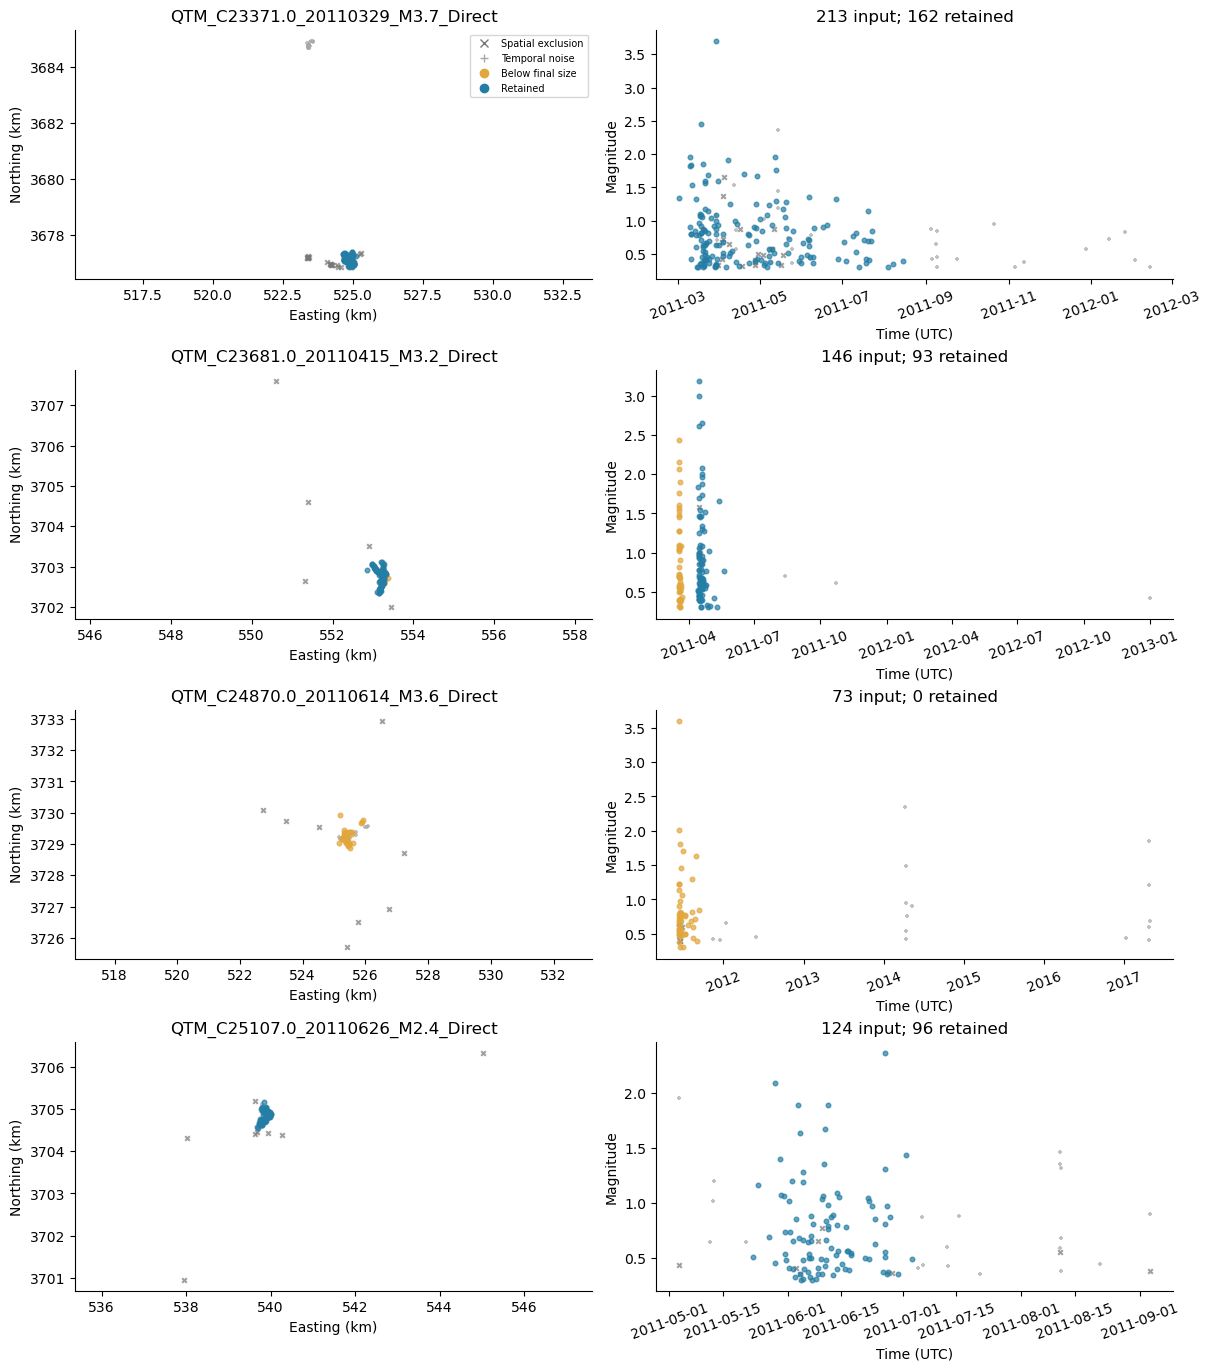

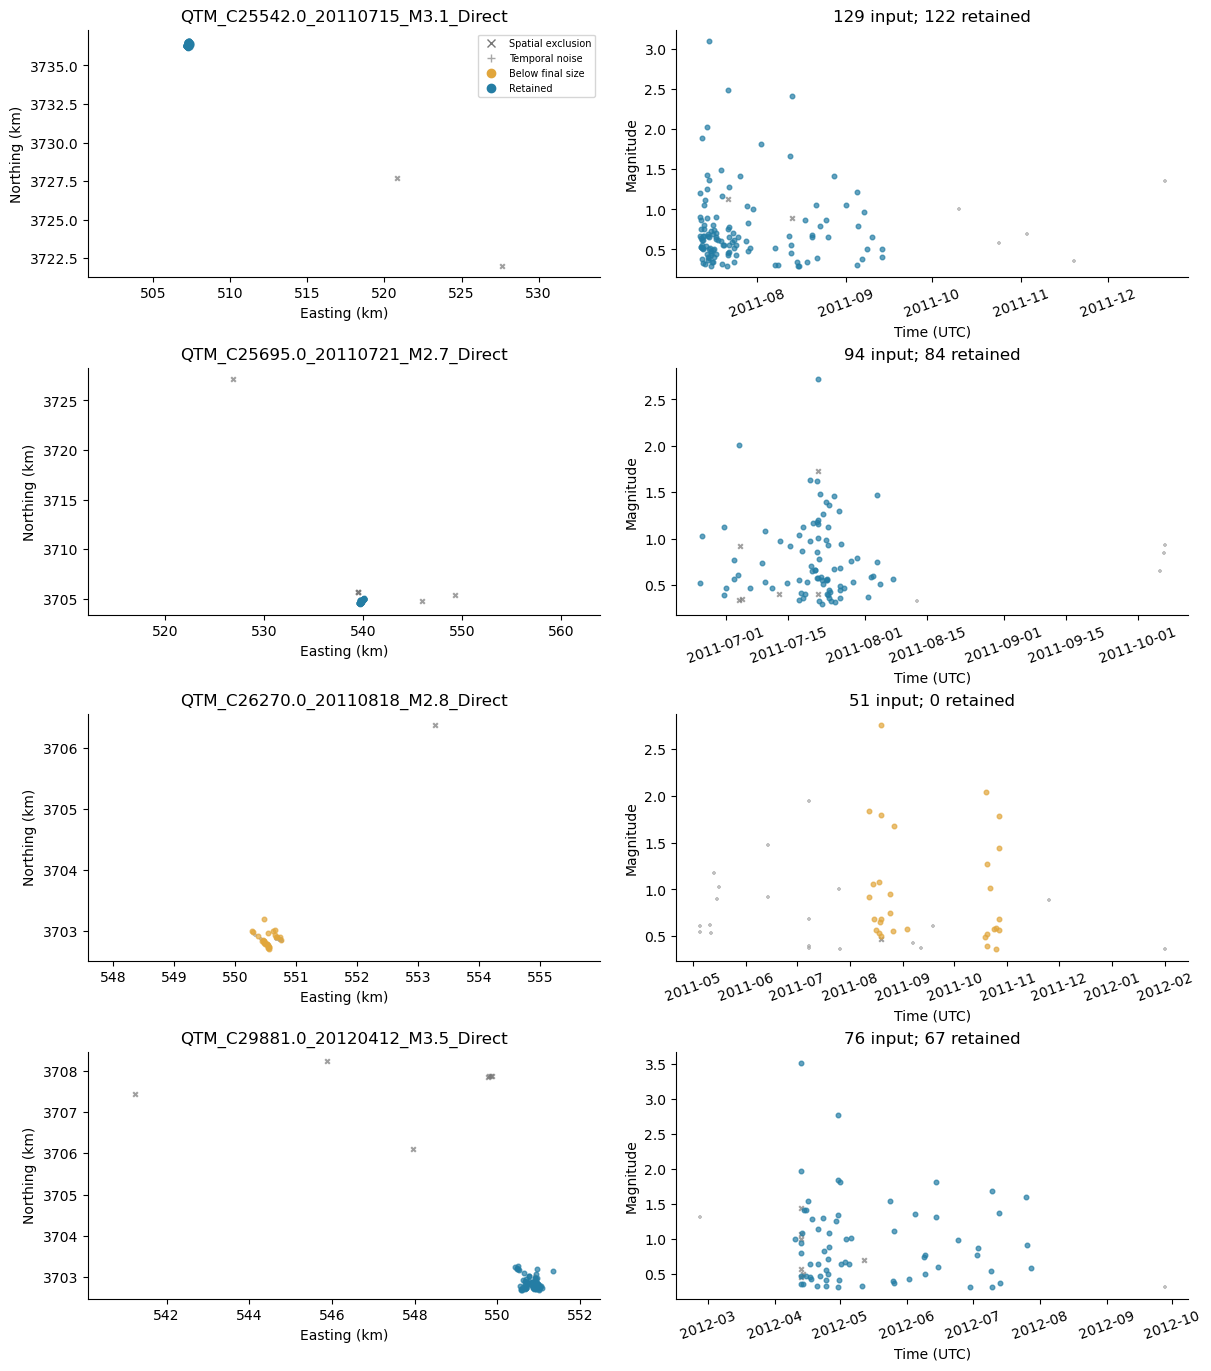

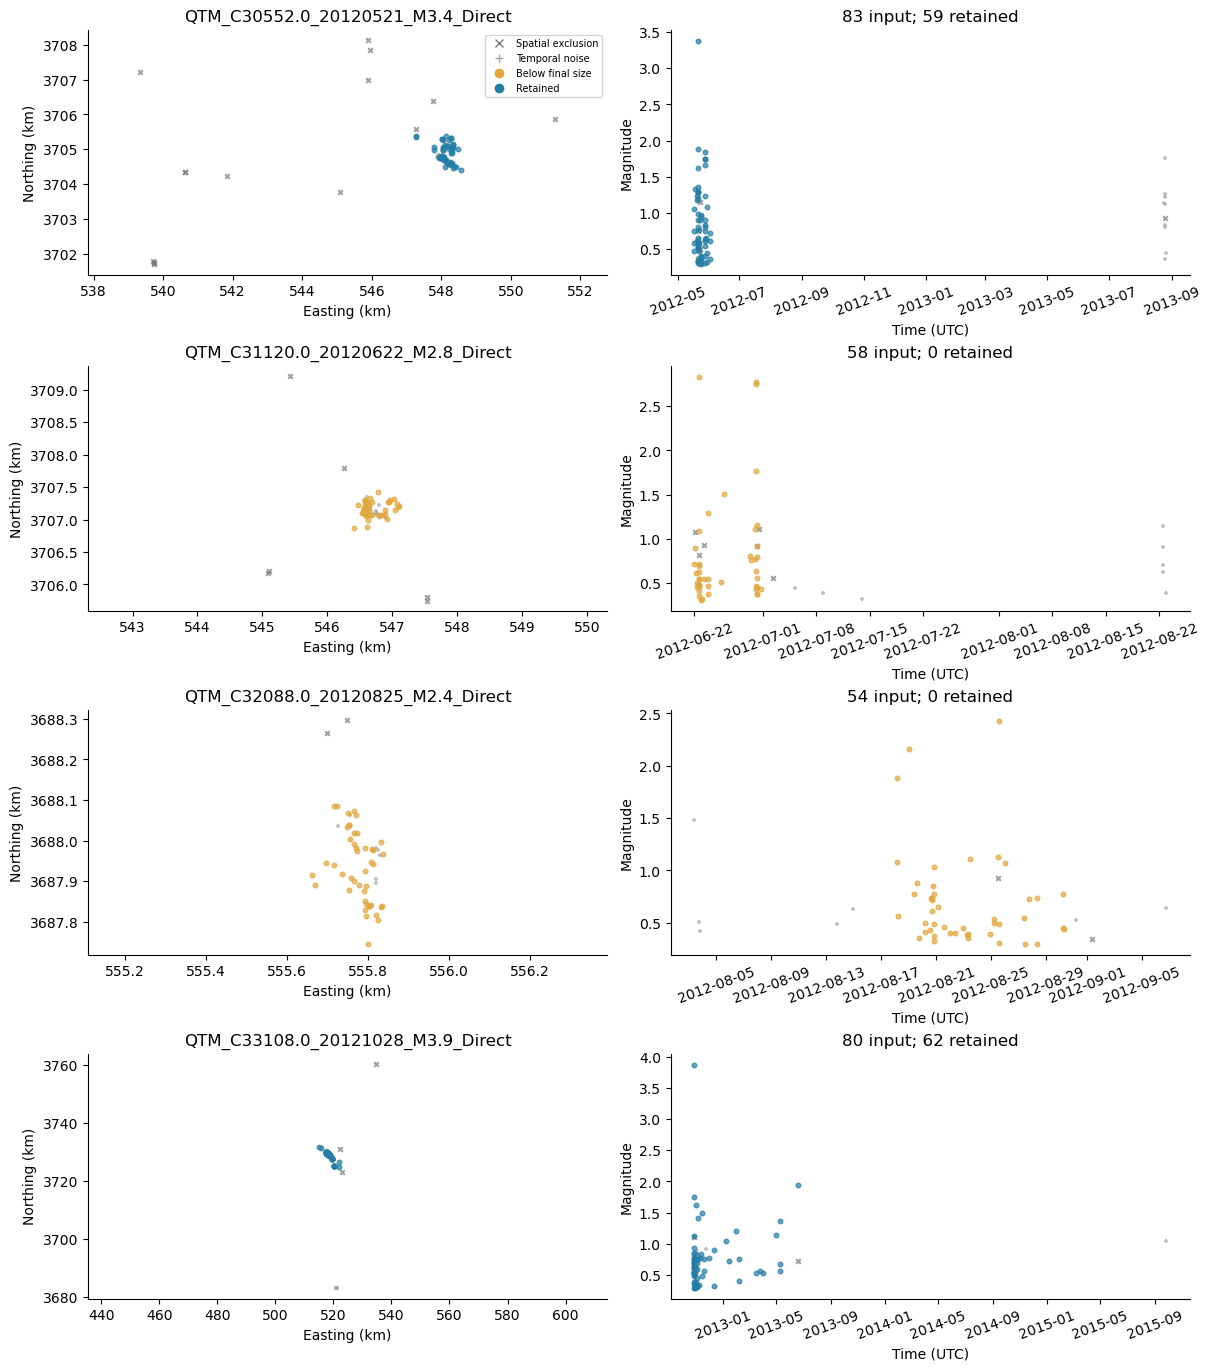

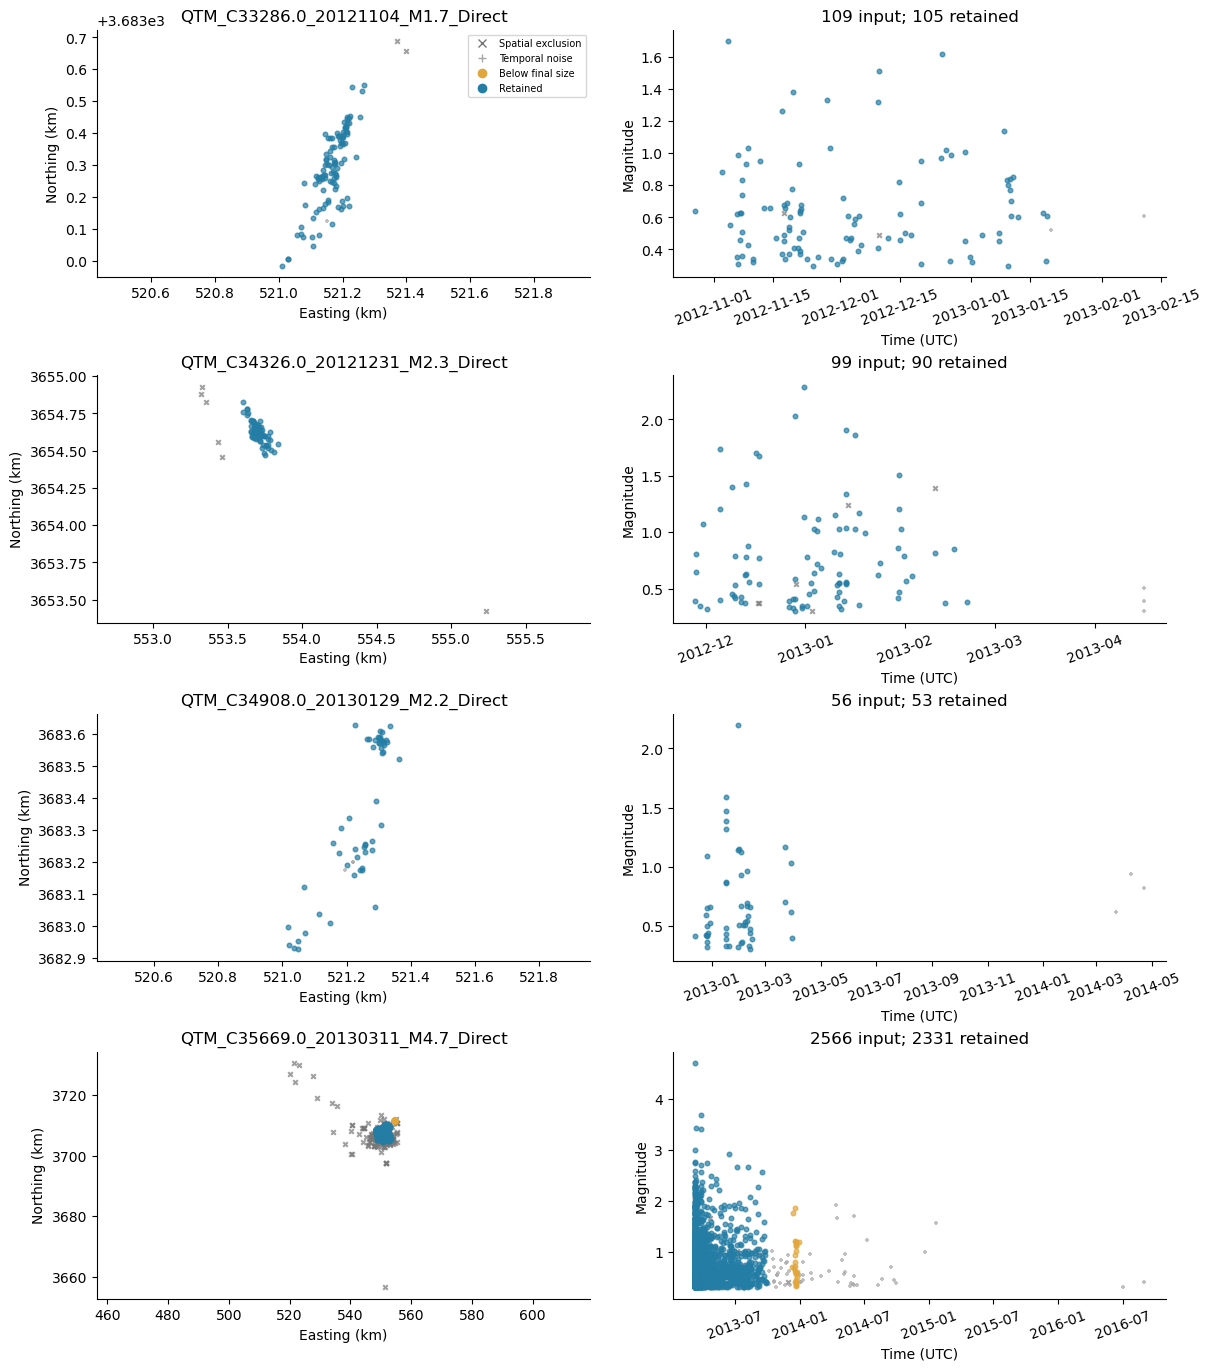

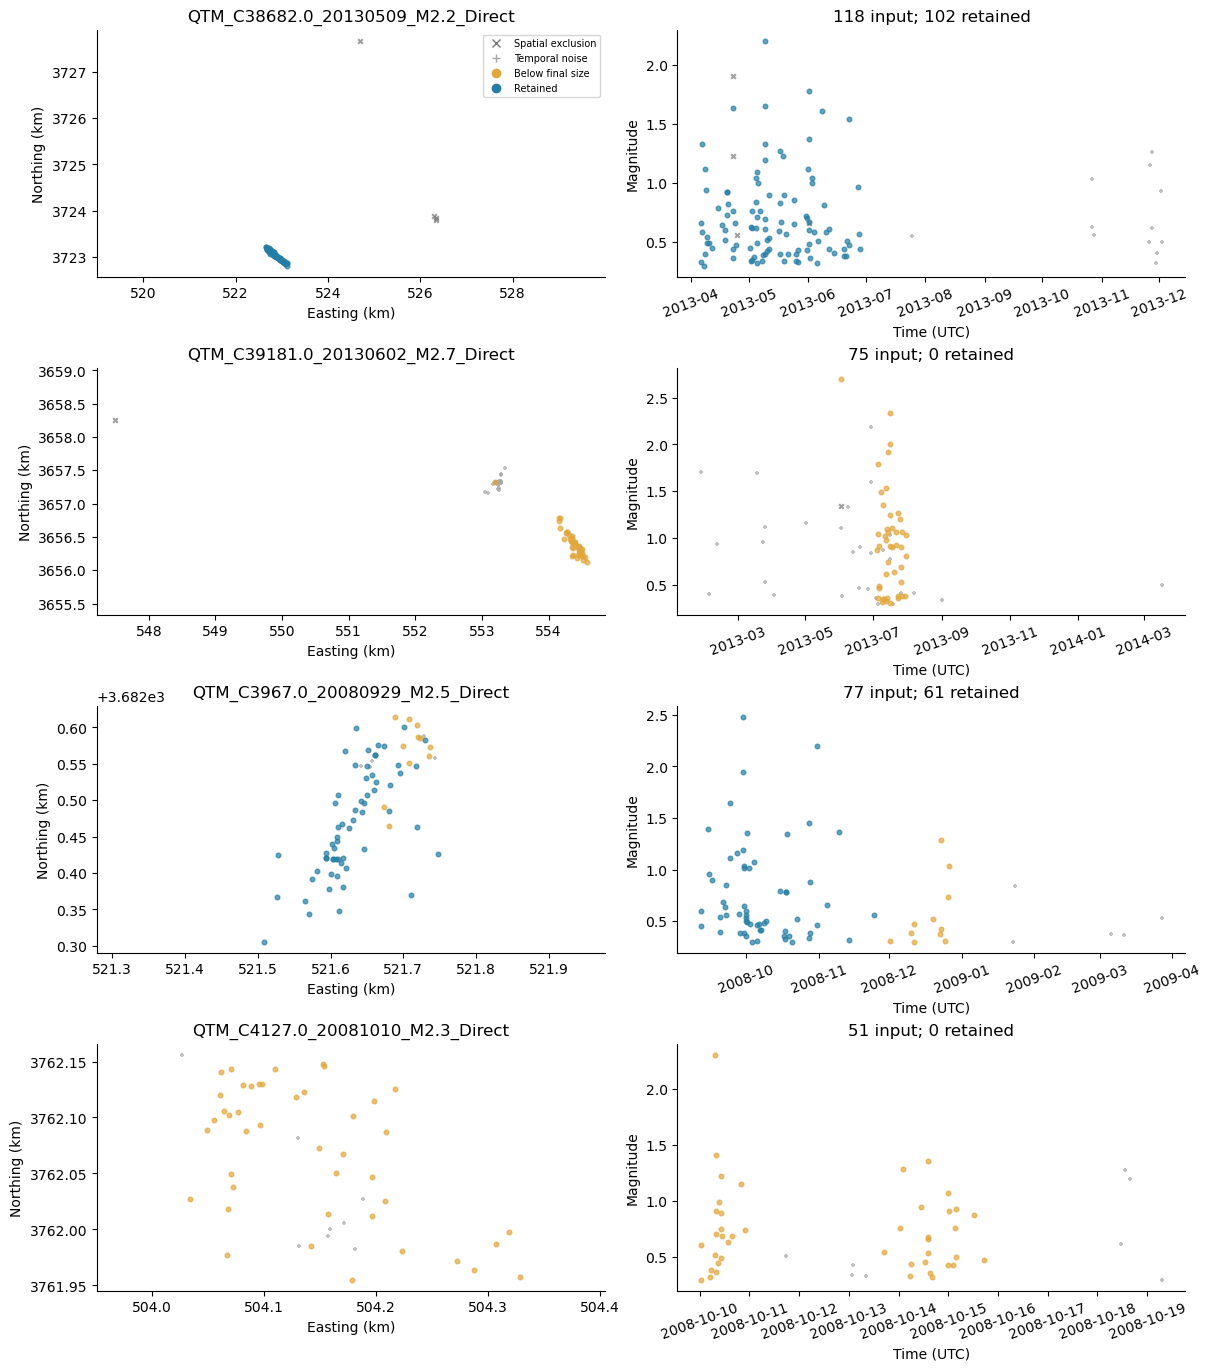

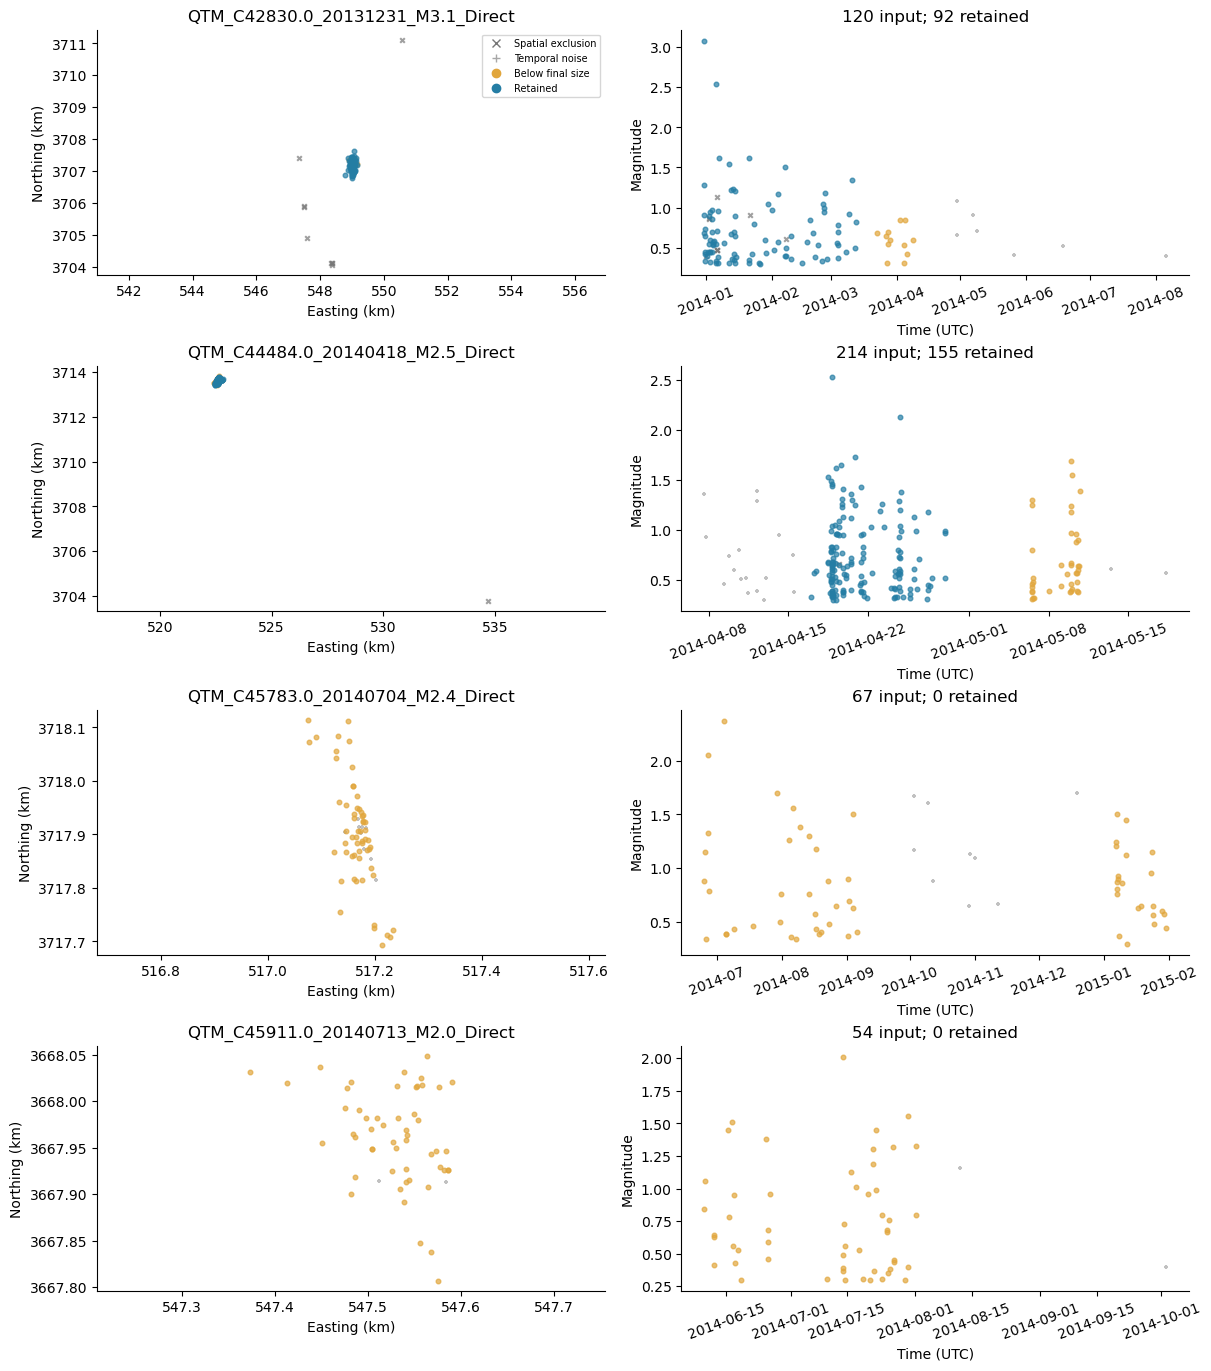

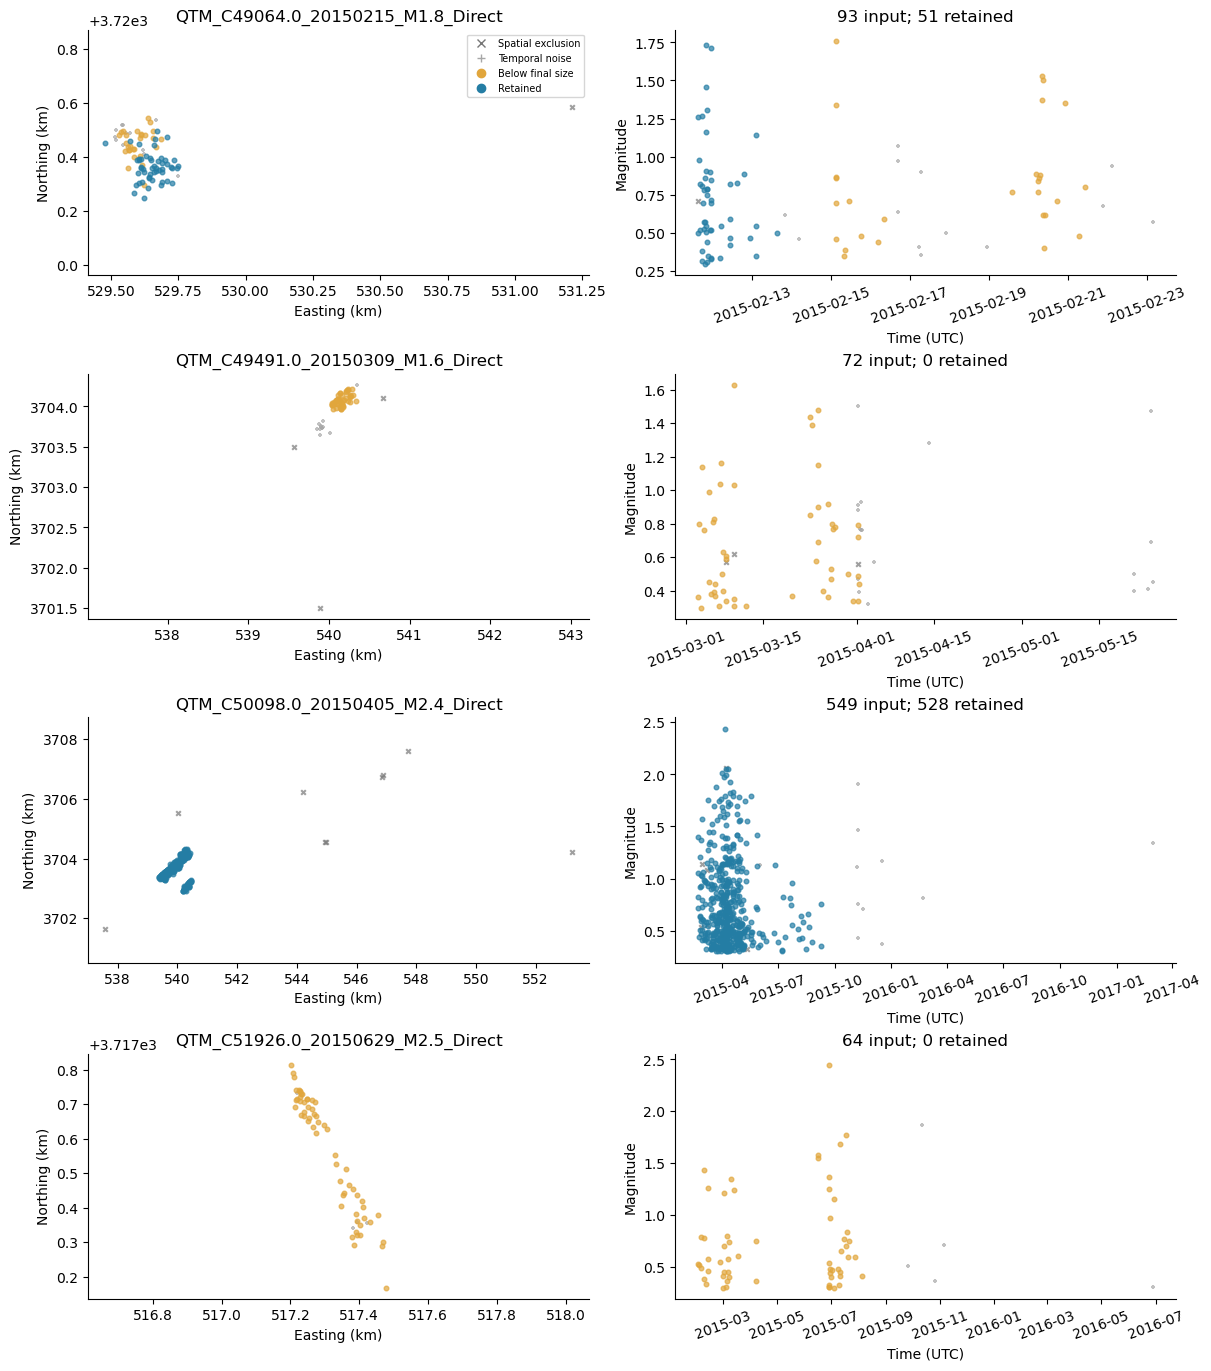

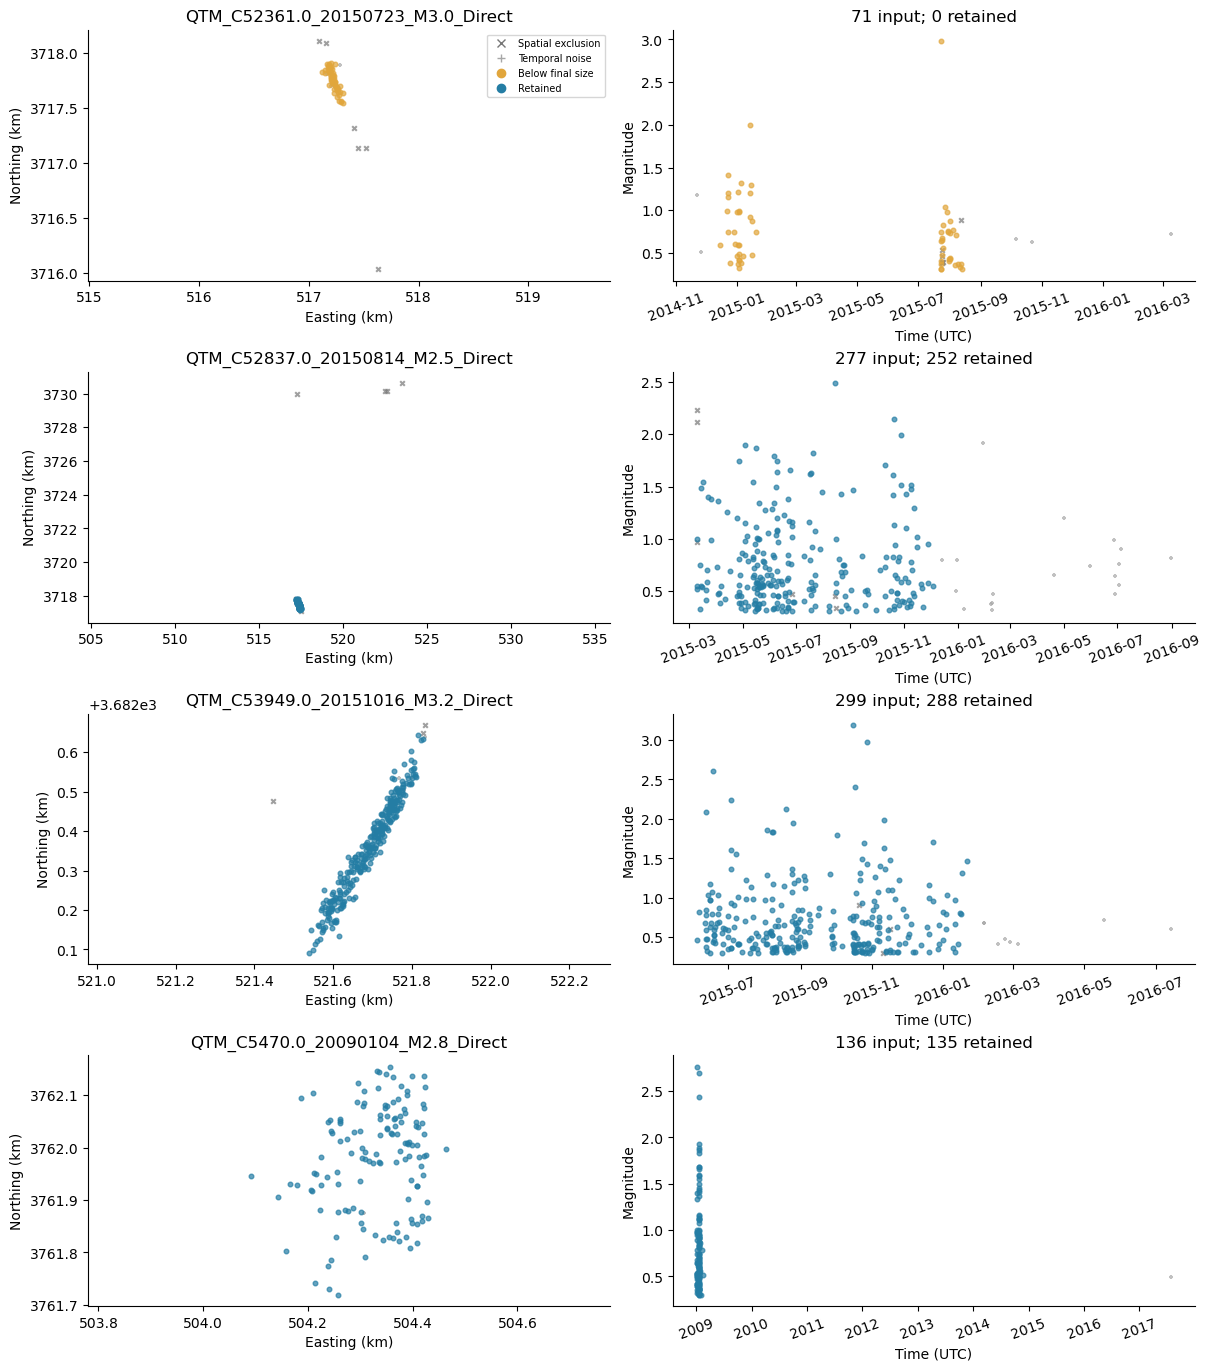

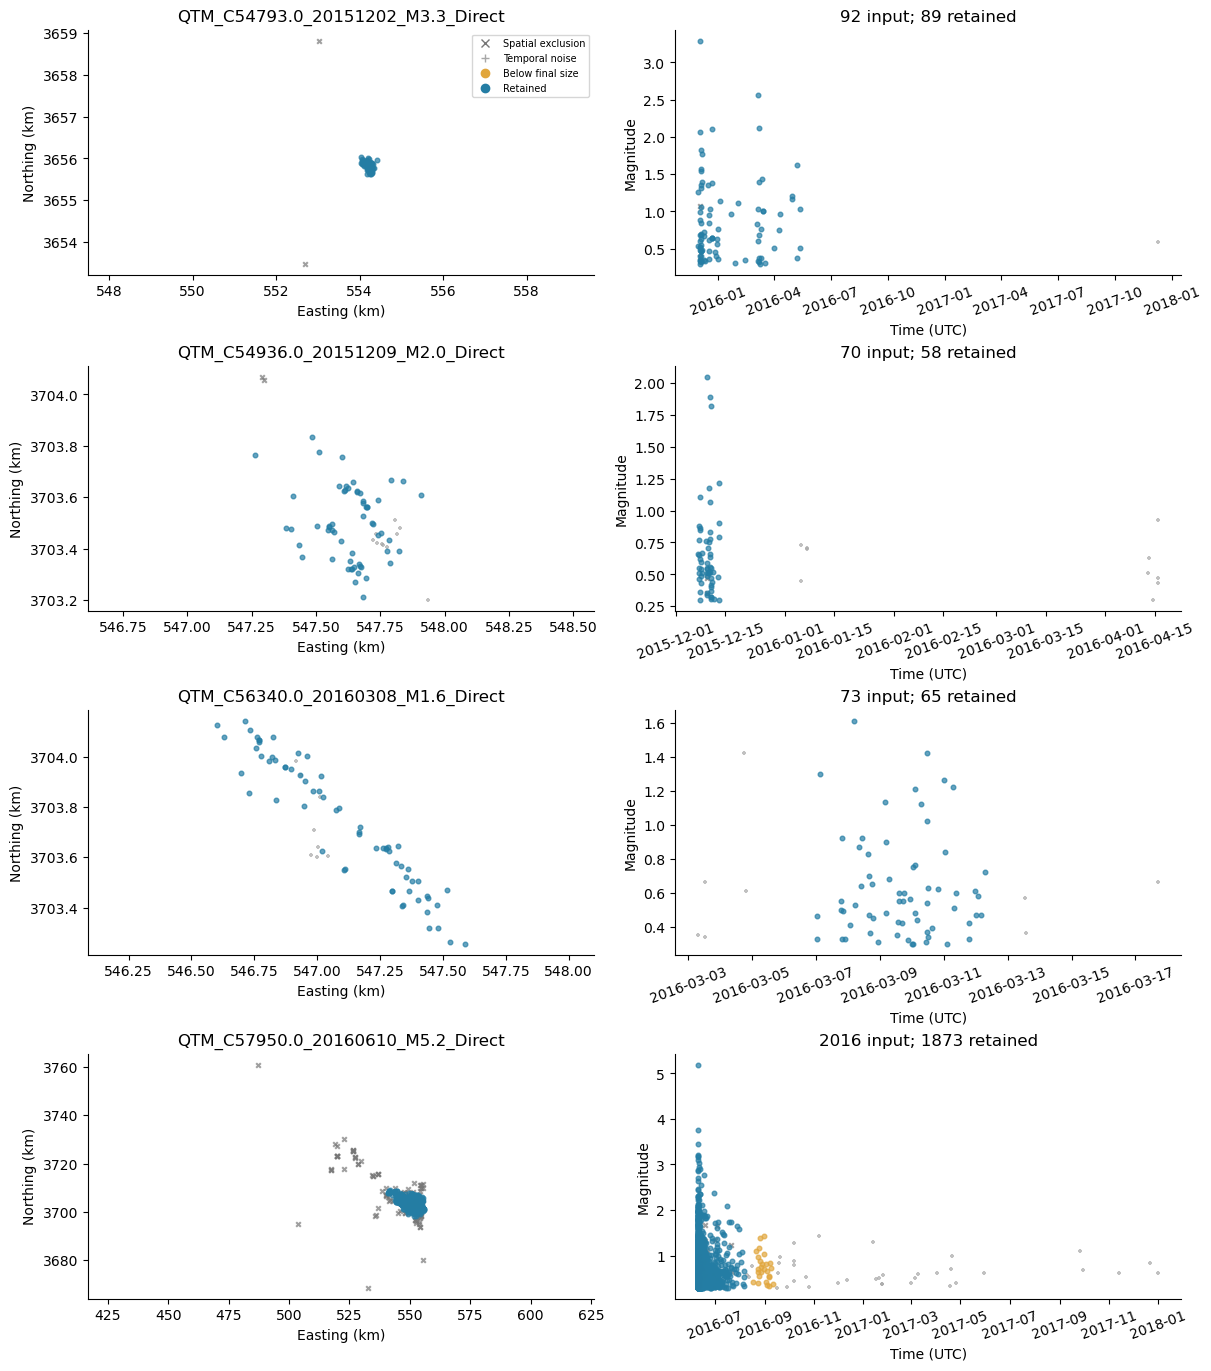

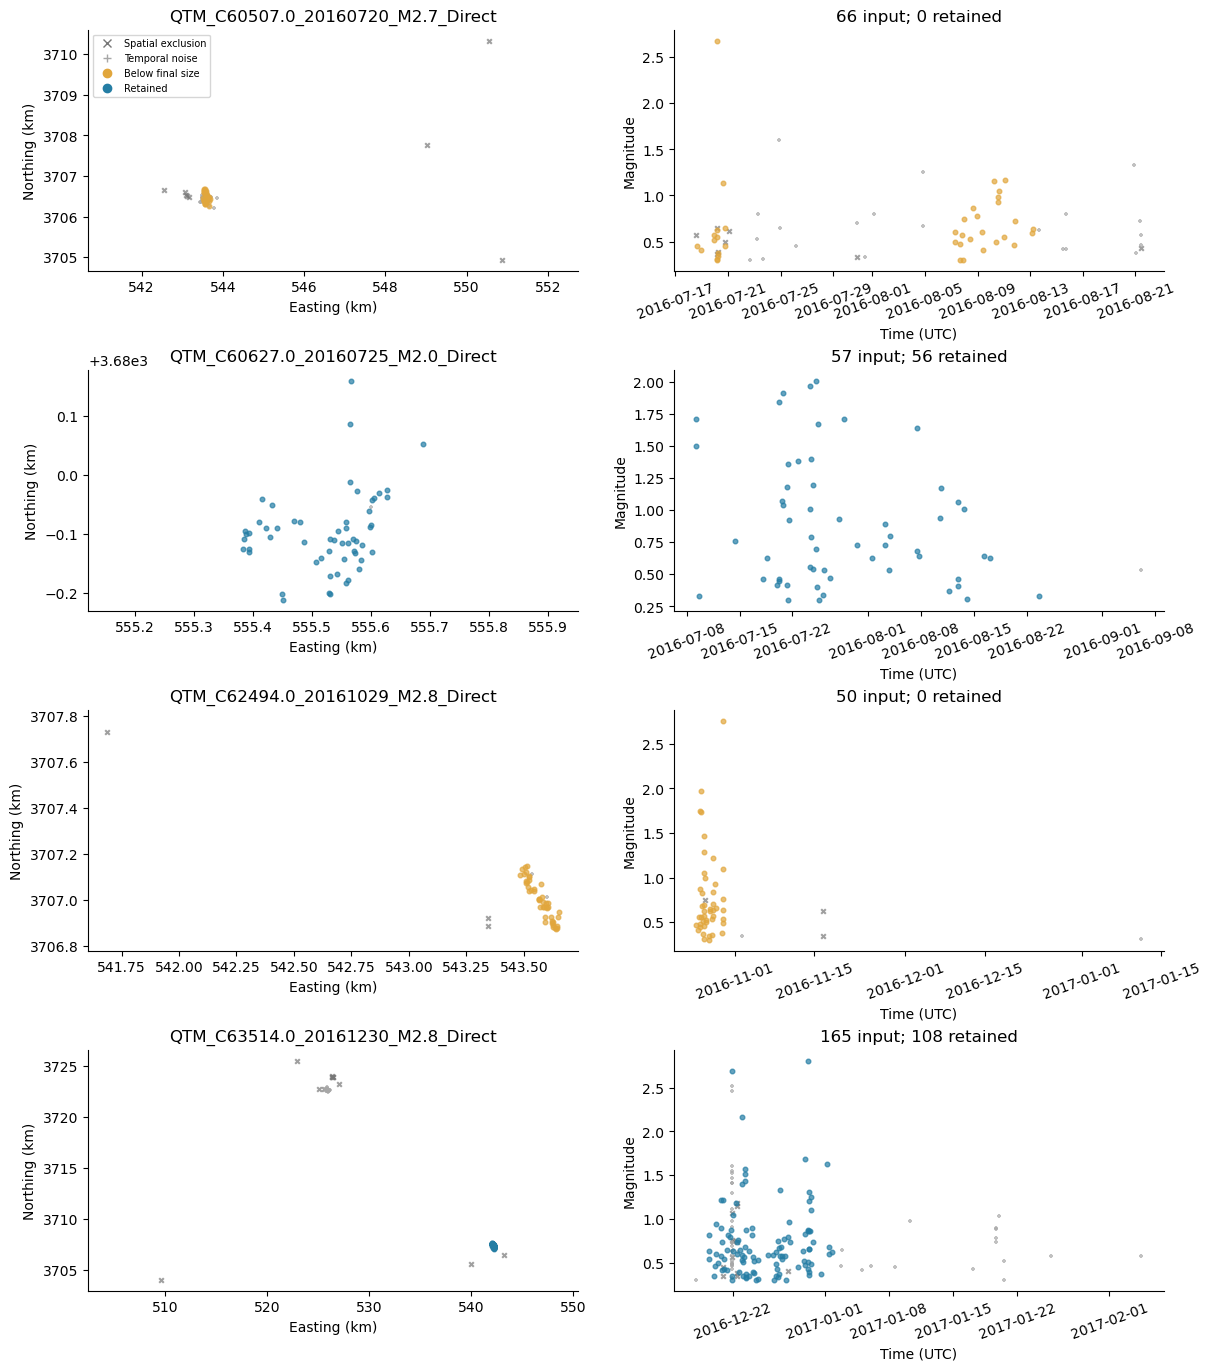

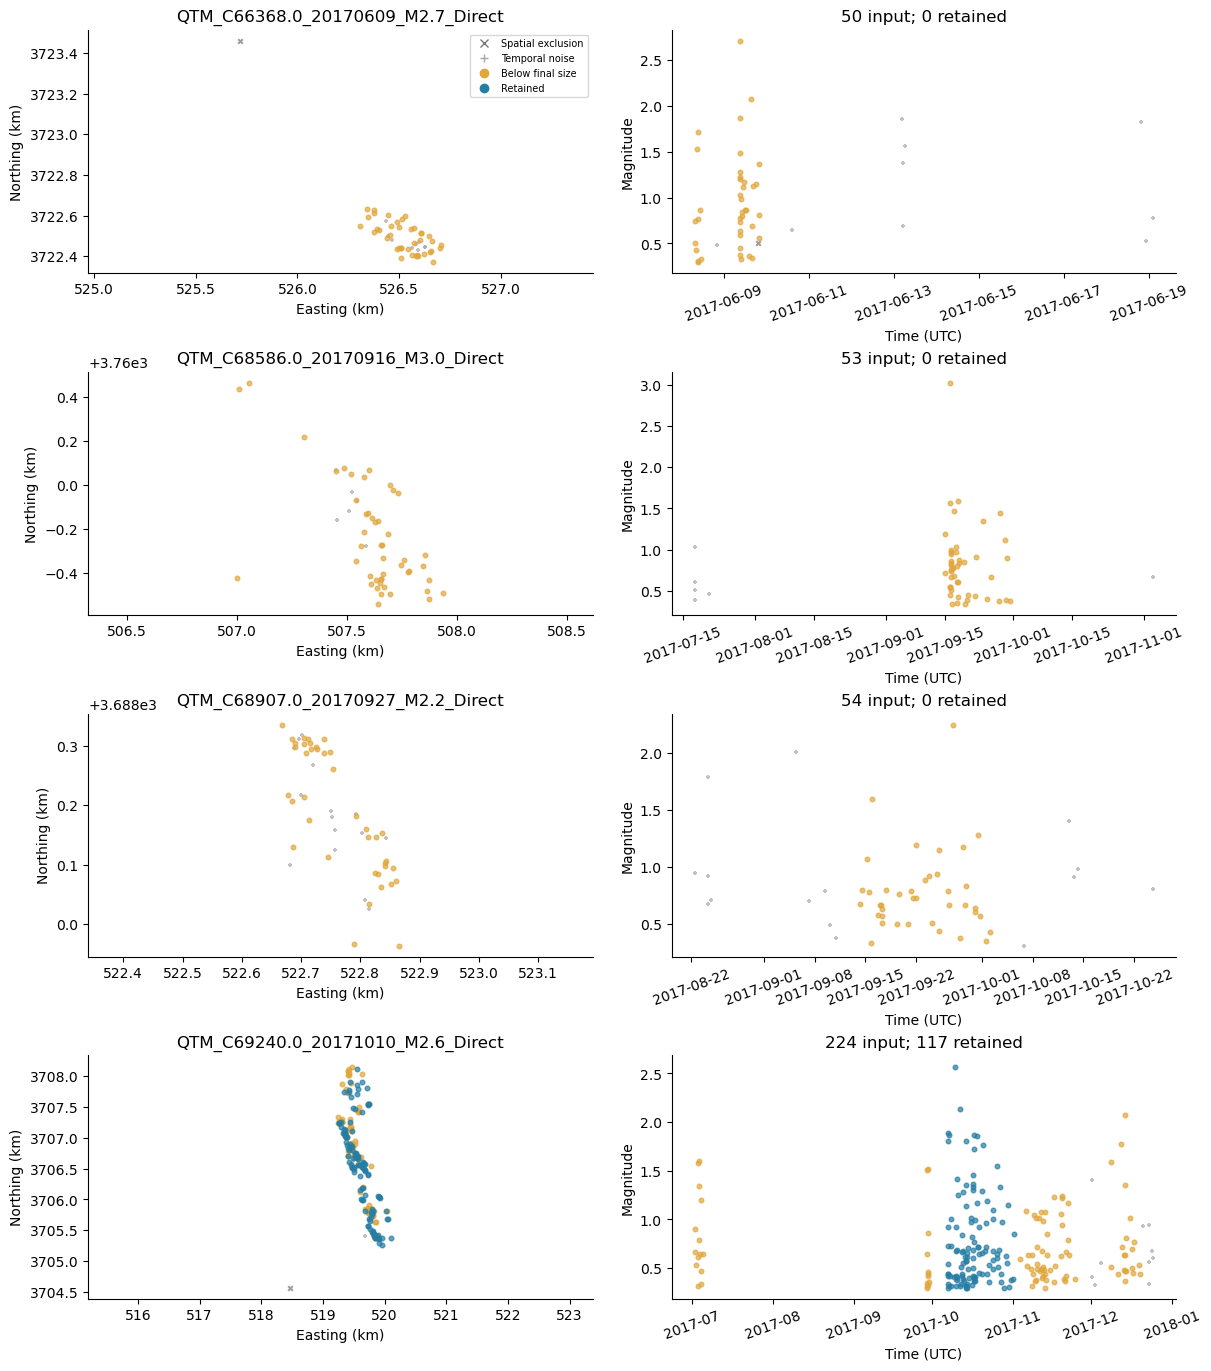

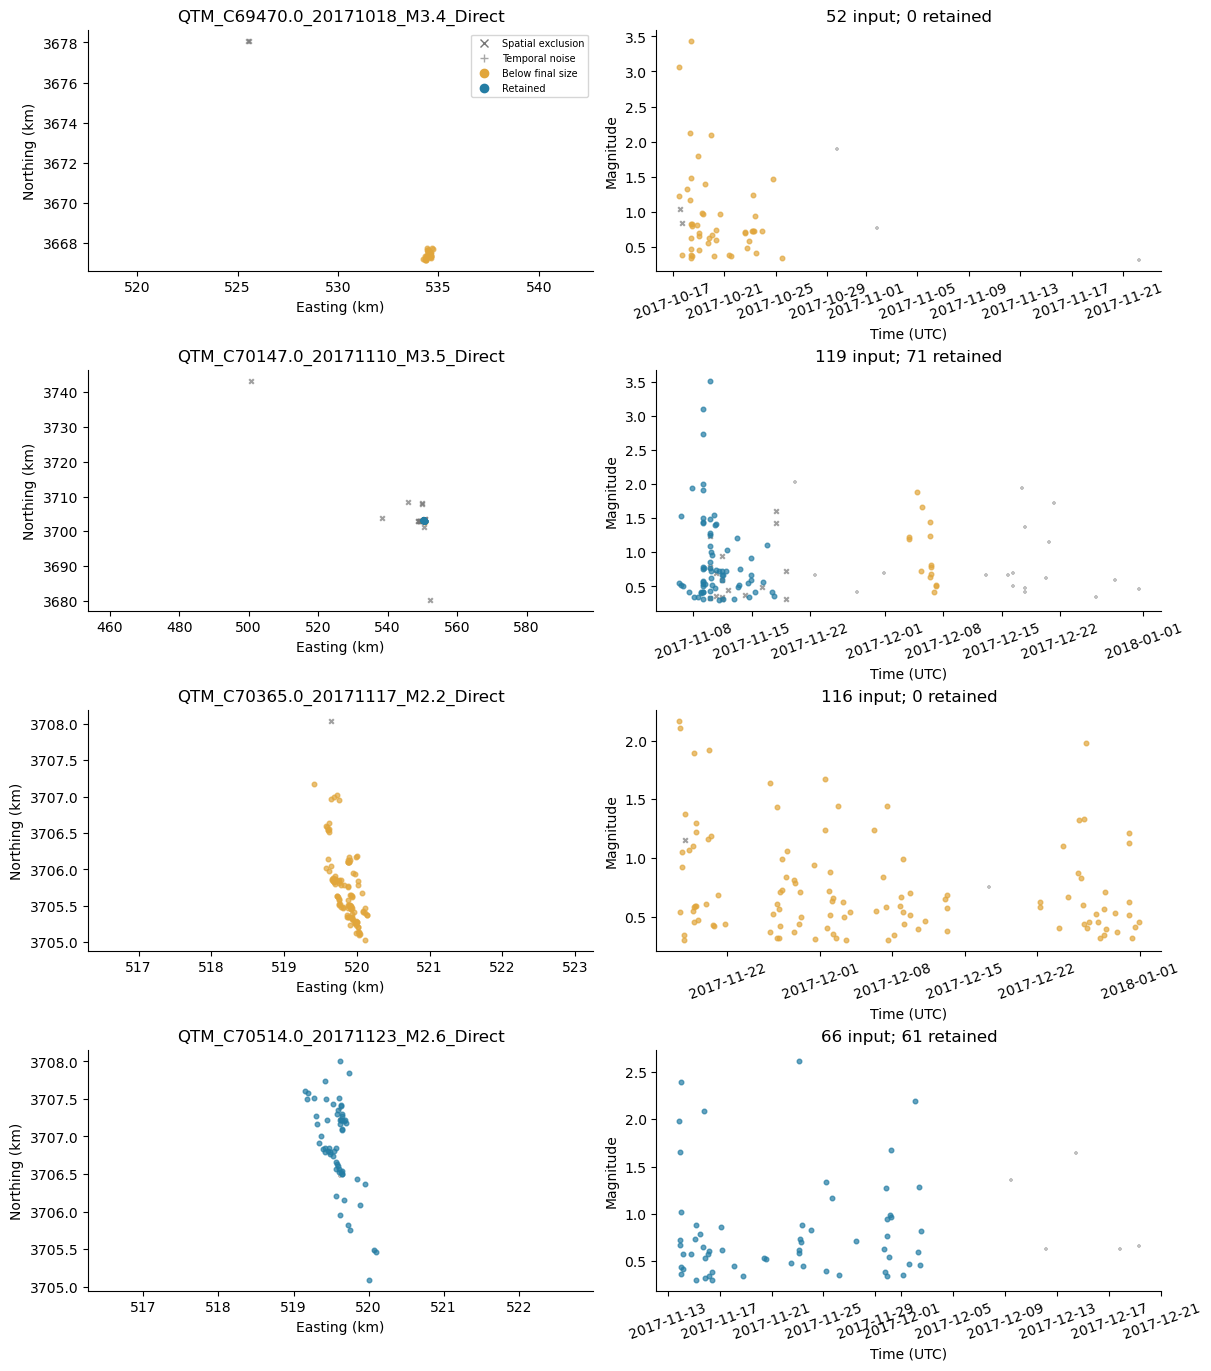

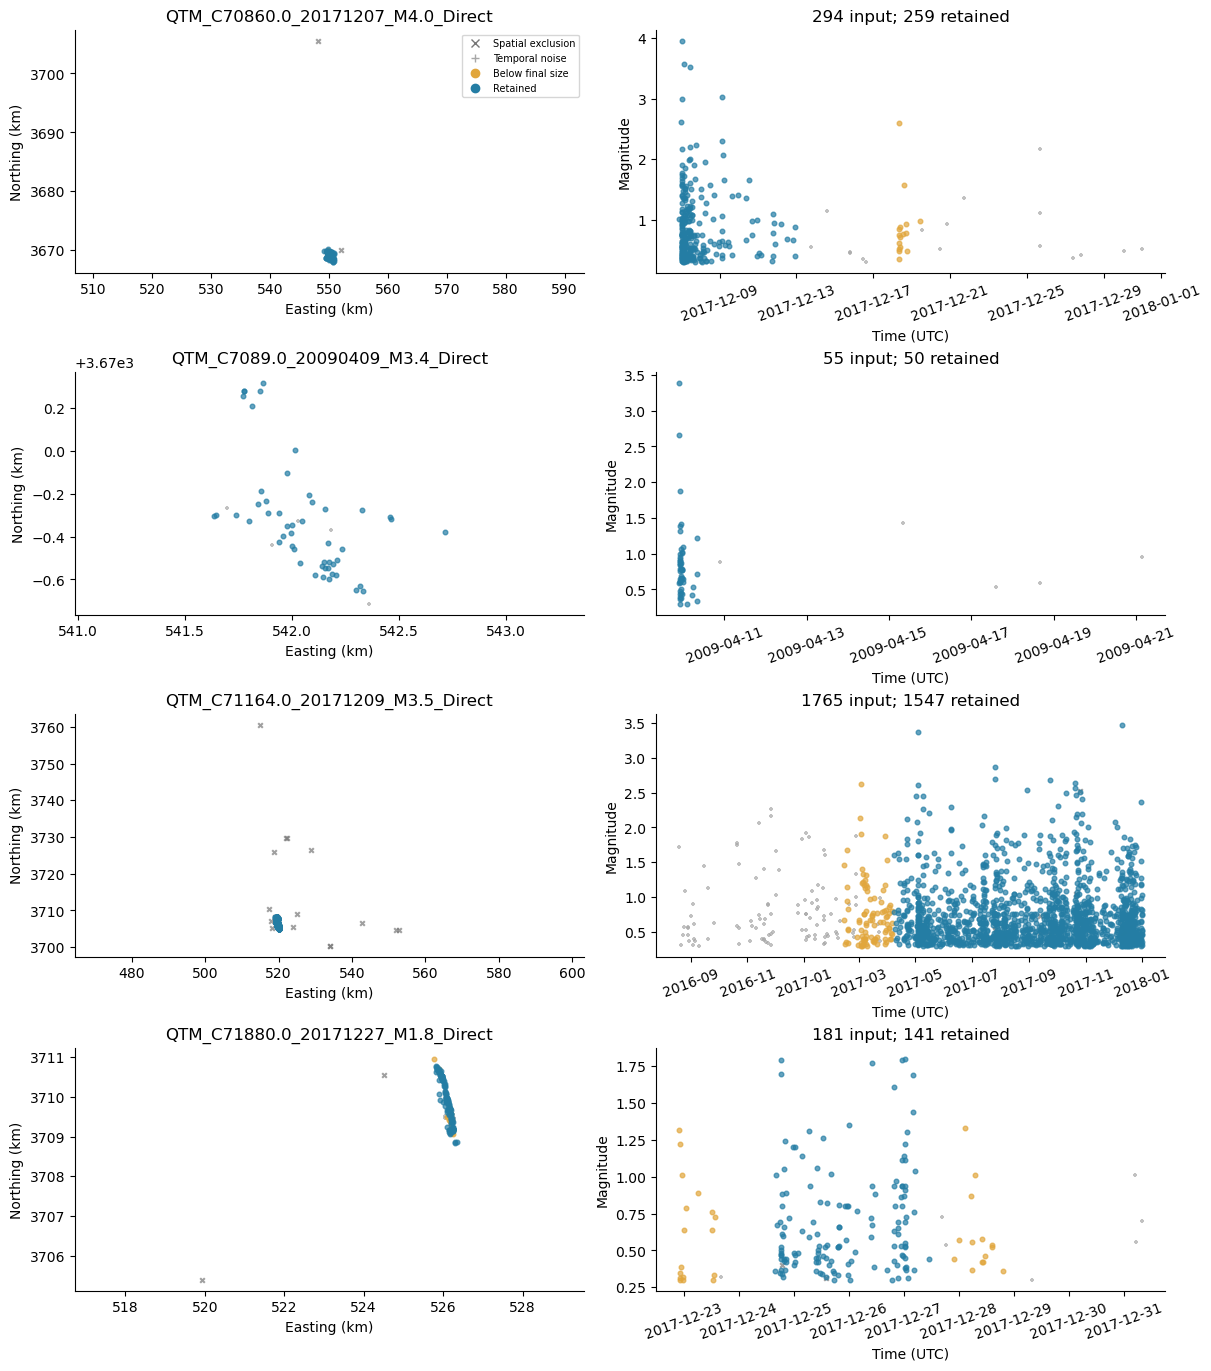

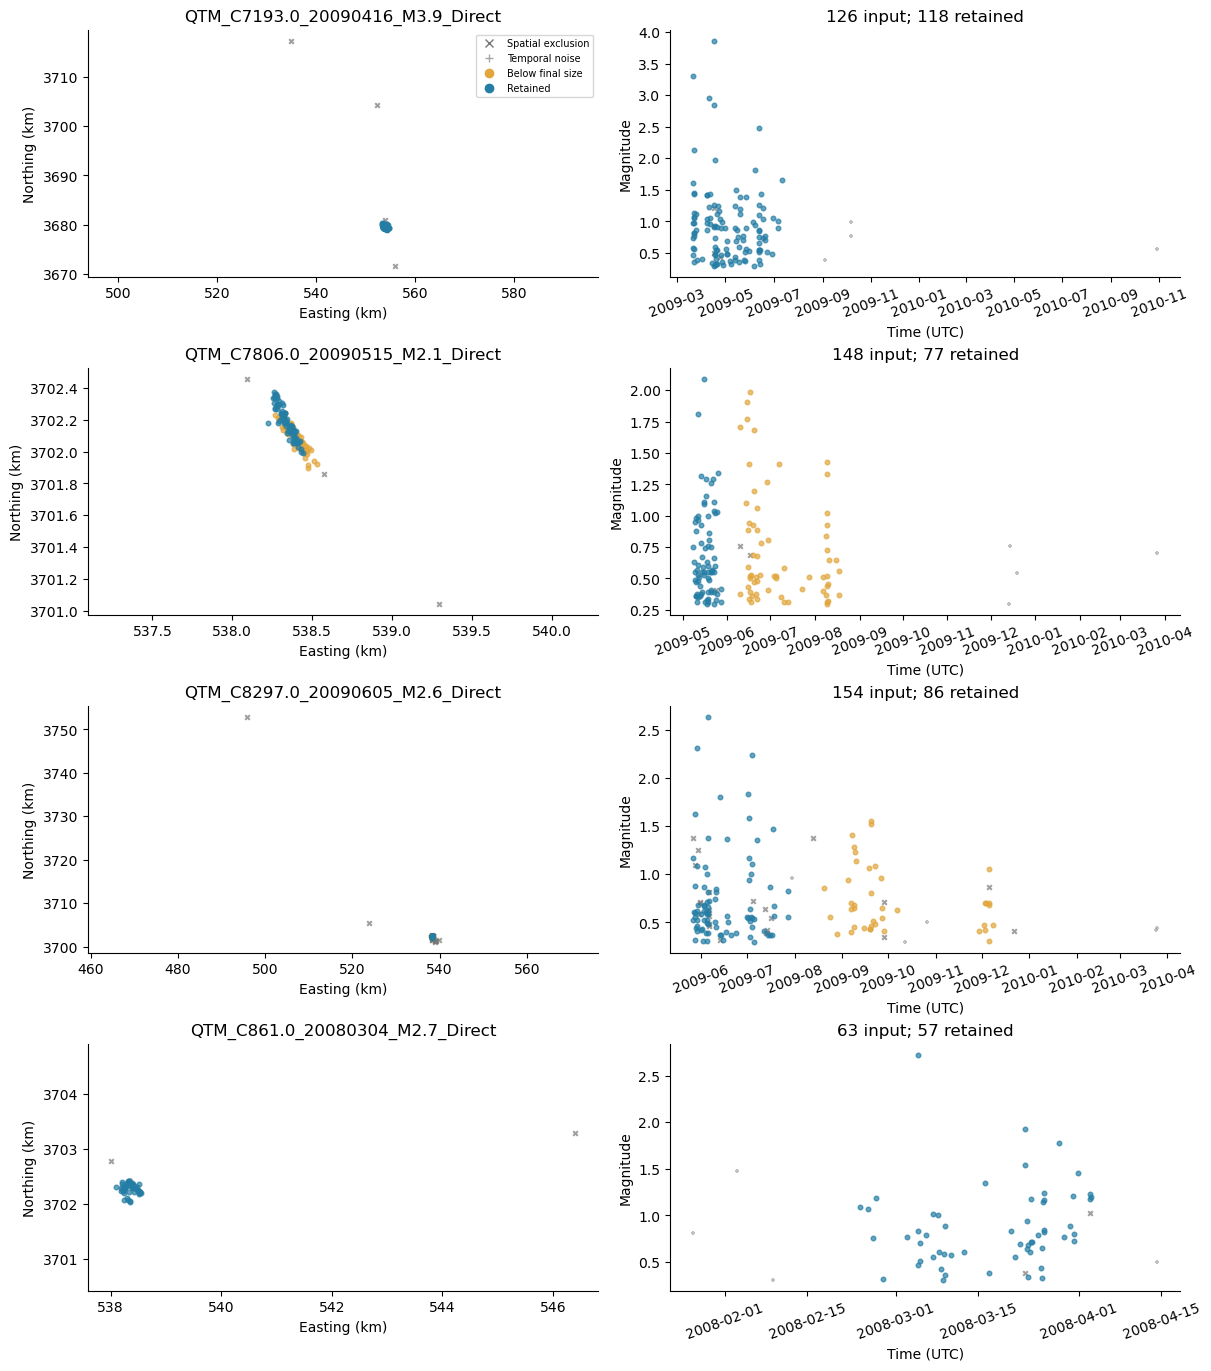

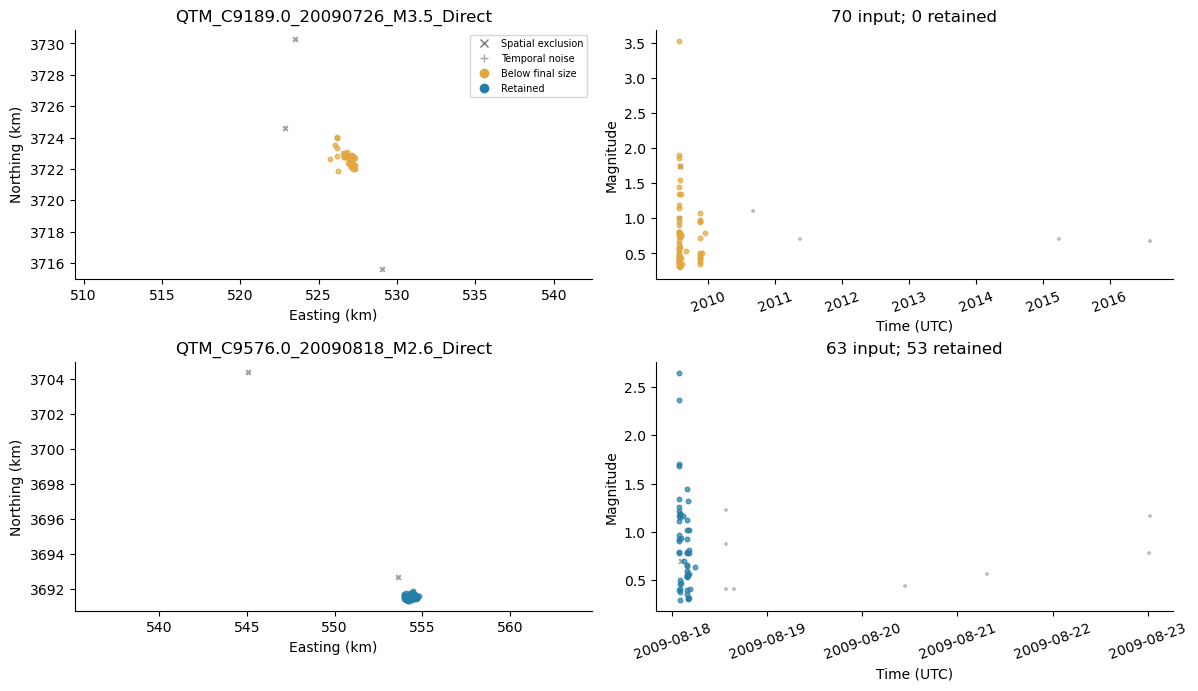

In [2]:
# Every eligible NNA group is shown. Each page contains up to four groups.
from matplotlib.lines import Line2D
for offset in range(0, len(files), 4):
    page = files[offset:offset + 4]
    fig, axes = plt.subplots(len(page), 2, figsize=(12, 3.4 * len(page)), squeeze=False, constrained_layout=True)
    for row, path in enumerate(page):
        df = pd.read_csv(path)
        df["datetime"] = pd.to_datetime(df["datetime"], format="mixed", utc=True)
        retained = df.refined_cluster.ge(0)
        spatial = df.spatial_excluded.astype(bool)
        small = df.final_cluster.ge(0) & ~retained
        noise = ~spatial & df.final_cluster.lt(0)
        for mask, color, marker, label in [(spatial, "#777777", "x", "Spatial exclusion"),
                                           (noise, "#a7a7a7", "+", "Temporal noise"),
                                           (small, "#e1a63c", "o", "Below final size"),
                                           (retained, "#247da4", "o", "Retained")]:
            axes[row, 0].scatter(df.loc[mask, "x"], df.loc[mask, "y"], c=color, marker=marker, s=11, alpha=.7, label=label)
            axes[row, 1].scatter(df.loc[mask, "datetime"], df.loc[mask, "mag"], c=color, marker=marker, s=11, alpha=.7)
        axes[row, 0].set(xlabel="Easting (km)", ylabel="Northing (km)", title=path.stem.replace("refined_", ""))
        axes[row, 0].set_aspect("equal", adjustable="datalim")
        axes[row, 1].set(xlabel="Time (UTC)", ylabel="Magnitude", title=f"{len(df)} input; {retained.sum()} retained")
        axes[row, 1].tick_params(axis="x", rotation=20)
    handles = [Line2D([0], [0], marker=m, color=c, ls="", label=l) for m,c,l in [("x","#777777","Spatial exclusion"),("+","#a7a7a7","Temporal noise"),("o","#e1a63c","Below final size"),("o","#247da4","Retained")]]
    axes[0, 0].legend(handles=handles, fontsize=7, loc="best")
    plt.show()

The “below final size” category may contain coherent candidate groups; it is not equivalent to DBSCAN noise. Proceed to `03_classification.ipynb`.